# Policy gradient methods: from REINFORCE to PPO

Train a small policy on **MinAtar Breakout**, evaluate it on fresh episodes, and watch its decisions. Read the cells in order; the rollout and optimizer loops are visible here.

In [11]:
%matplotlib inline

from pathlib import Path
import csv
import json
import sys
import time
from importlib.metadata import version

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.distributions import Categorical
from IPython.display import Image, display

# Works when Jupyter starts at the repository root or in this notebook's folder.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/math550/topics/reinforcement").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the MATH550 coding repository.")
sys.path.insert(0, str(ROOT / "src"))

from math550.topics.reinforcement import (
    MinAtarAdapter, resolve_torch_device, rollout_minatar_policy,
    render_minatar_policy_frame, save_minatar_policy_animation,
)

DEVICE = "auto"  # "cuda", "mps", or "cpu" also work; unavailable requests raise an error.
device = resolve_torch_device(DEVICE)
torch.set_num_threads(1)  # Small networks usually need little CPU parallelism.
SEED = 550
np.random.seed(SEED)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

OUT = ROOT / "output/reinforcement/notebook_demo"
OUT.mkdir(parents=True, exist_ok=True)
print(f"Device: {device} | PyTorch: {torch.__version__} | MinAtar: {version('minatar')}")


Device: mps | PyTorch: 2.13.0 | MinAtar: 1.0.15


## 1. The policy gradient is a weighted log-probability gradient

The policy outputs a categorical distribution over actions. Sampling an action produces experience; gradient ascent then increases log probability for actions with positive advantage:

$$
\nabla_\theta J \approx \frac1B\sum_t
\hat A_t\,\nabla_\theta\log\pi_\theta(a_t\mid s_t).
$$

REINFORCE uses a sampled return (possibly minus a baseline) as the weight. Here the critic estimates $V(s)$ and GAE estimates the advantage. Freeze those weights during the policy update: in PyTorch, use `.detach()`.

PPO reuses a rollout for a few minibatch epochs. At a fixed sampled state, define
$$
r_t=\exp(\log\pi_\theta(a_t\mid s_t)-\log\pi_{\rm old}(a_t\mid s_t)),\qquad
L_t=\min(r_t\hat A_t,\operatorname{clip}(r_t,1-\epsilon,1+\epsilon)\hat A_t).
$$

In a live region, $\nabla L_t=r_t\hat A_t\nabla\log\pi_\theta$. Positive advantages saturate only above $1+\epsilon$; negative ones saturate only below $1-\epsilon$. The next cell checks all four cases by autograd.


In [12]:
ratios = torch.tensor([1.35, 0.70, 1.35, 0.70])
advantages_demo = torch.tensor([2.0, 2.0, -2.0, -2.0])
logp_demo = ratios.log().requires_grad_()  # Old log probability is zero in this example.
ratio_demo = logp_demo.exp()
surrogate_demo = torch.minimum(
    ratio_demo * advantages_demo,
    ratio_demo.clamp(0.8, 1.2) * advantages_demo,
)
surrogate_demo.sum().backward()  # Ascent gradient; training minimizes its negative.
print("ratio | advantage | coefficient on grad(log pi)")
for r, a, g in zip(ratios, advantages_demo, logp_demo.grad):
    print(f"{r:5.2f} | {a:9.1f} | {g:8.2f}")
torch.testing.assert_close(logp_demo.grad, torch.tensor([0.0, 1.4, -2.7, 0.0]))


ratio | advantage | coefficient on grad(log pi)
 1.35 |       2.0 |     0.00
 0.70 |       2.0 |     1.40
 1.35 |      -2.0 |    -2.70
 0.70 |      -2.0 |     0.00


## 2. A small visual environment and one actor–critic

Each observation is a $10\times10\times4$ binary array: paddle, ball, ball trail, and bricks. The course adapter exposes **0 = left, 1 = right, 2 = no-op** (raw MinAtar actions 1, 3, 0). Rewards count bricks hit. MinAtar repeats the preceding action with probability 0.1; the policy chooses a requested action.

The public environment supplies dynamics. We generate fresh training experience online; no dataset download or Atari ROM is needed. Source: [MinAtar](https://github.com/kenjyoung/MinAtar), version 1.0.15, GPL-3.0.

The model matches the current course actor–critic: two convolution layers, a shared hidden layer, then policy logits and a scalar value. The observation helper just changes arrays from NHWC to PyTorch's NCHW layout.


In [13]:
NUM_ENVS = 8
ROLLOUT_STEPS = 128
NUM_UPDATES = 32  # 8 x 128 x 32 = 32,768 training interactions.
UPDATE_EPOCHS = 4
MINIBATCH_SIZE = 256
GAMMA, GAE_LAMBDA = 0.99, 0.95
CLIP_EPS = 0.2
LEARNING_RATE = 2.5e-4
VALUE_COEF, ENTROPY_COEF = 0.5, 0.01
TARGET_KL = 0.03
EVAL_EPISODES, EVAL_MAX_STEPS = 20, 1000

envs = [MinAtarAdapter("breakout", seed=SEED + i) for i in range(NUM_ENVS)]
action_names = envs[0].action_names

def obs_tensor(observations):
    return torch.as_tensor(np.asarray(observations), dtype=torch.float32,
                           device=device).permute(0, 3, 1, 2).contiguous()

class ActorCritic(nn.Module):
    def __init__(self):
        super().__init__()
        self.trunk = nn.Sequential(
            nn.Conv2d(4, 16, 3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.Flatten(), nn.Linear(32 * 10 * 10, 128), nn.ReLU(),
        )
        self.actor = nn.Linear(128, len(action_names))
        self.critic = nn.Linear(128, 1)
        for layer in self.modules():
            if isinstance(layer, (nn.Conv2d, nn.Linear)):
                nn.init.orthogonal_(layer.weight, gain=np.sqrt(2))
                nn.init.zeros_(layer.bias)
        nn.init.orthogonal_(self.actor.weight, gain=0.01)
        nn.init.orthogonal_(self.critic.weight, gain=1.0)

    def forward(self, observations):
        h = self.trunk(observations)
        return self.actor(h), self.critic(h).squeeze(-1)

policy = ActorCritic().to(device)
optimizer = torch.optim.Adam(policy.parameters(), lr=LEARNING_RATE, eps=1e-5)
with torch.no_grad():
    sample_logits, sample_values = policy(obs_tensor([envs[0].reset()]))
assert sample_logits.shape == (1, 3) and sample_values.shape == (1,)
print(f"Actions: {action_names} | parameters: {sum(p.numel() for p in policy.parameters()):,}")
print(f"Training budget: {NUM_ENVS * ROLLOUT_STEPS * NUM_UPDATES:,} interactions")


Actions: ('left', 'right', 'no-op') | parameters: 415,476
Training budget: 32,768 interactions


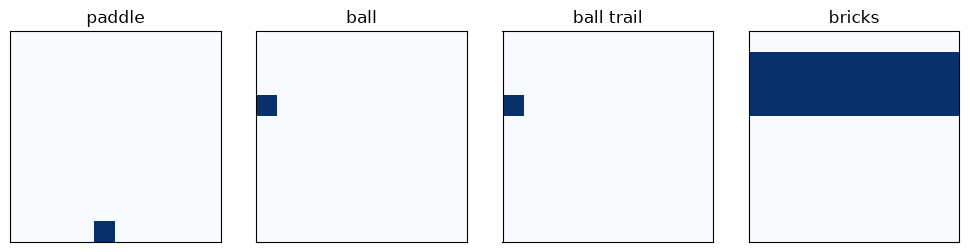

In [14]:
observation = envs[0].reset()
fig, axes = plt.subplots(1, 4, figsize=(10, 2.5))
for c, (ax, name) in enumerate(zip(axes, ["paddle", "ball", "ball trail", "bricks"])):
    ax.imshow(observation[:, :, c], cmap="Blues", vmin=0, vmax=1)
    ax.set(title=name, xticks=[], yticks=[])
fig.tight_layout()
plt.show()


## 3. Fix the evaluation protocol before training

Evaluate uniform random and the initial greedy policy on 20 fixed seeds disjoint from training. After training, reuse those seed IDs and the same 1,000-step evaluation cap. Each seed creates a separate environment. Evaluation runs without gradients or optimizer steps.

We report greedy deployment behavior; training samples actions. Shared seed IDs help comparisons, but different policies can consume environment randomness differently. The final plot shows individual returns and descriptive standard errors. A small one-seed training run may show no improvement.


In [15]:
@torch.no_grad()
def evaluate(network, seeds):
    rows = []
    was_training = network.training if network is not None else False
    if network is not None:
        network.eval()
    for seed in seeds:
        env = MinAtarAdapter("breakout", seed=seed)
        action_rng = np.random.default_rng(seed)
        observation = env.reset()
        total_reward = 0.0
        for step in range(EVAL_MAX_STEPS):
            if network is None:
                action = int(action_rng.integers(env.action_count))
            else:
                logits, _ = network(obs_tensor([observation]))
                assert logits.shape == (1, env.action_count)
                action = int(logits.argmax(-1).item())
            observation, reward, done = env.step(action)
            total_reward += reward
            if done:
                break
        rows.append({"seed": int(seed), "return": total_reward,
                     "length": step + 1, "truncated": not done})
    if network is not None:
        network.train(was_training)
    return rows

eval_seeds = list(range(20_550, 20_550 + EVAL_EPISODES))
baseline = evaluate(None, eval_seeds)
before = evaluate(policy, eval_seeds)
for label, rows in [("Uniform random", baseline), ("Before training (greedy)", before)]:
    print(f"{label}: mean return {np.mean([r['return'] for r in rows]):.2f}")


Uniform random: mean return 0.25
Before training (greedy): mean return 0.70


## 4. Advantage estimates connect the critic to the actor

For a real terminal transition, $d_t=1$ and the future value is zero:
$$
\delta_t=r_t+\gamma(1-d_t)V_{\rm old}(s_{t+1})-V_{\rm old}(s_t),\qquad
\hat A_t=\delta_t+\gamma\lambda(1-d_t)\hat A_{t+1}.
$$

The critic target is $\hat V_t=\hat A_t+V_{\rm old}(s_t)$. The actor uses a normalized copy of the advantages.

Arrays below have shape **time × environments**. A rollout boundary is only a collection boundary: bootstrap from its last next state. Training resets an environment only on a real game-over, so it needs no artificial time-limit handling. Terminal masks prevent a new episode from leaking into the previous episode's return.


In [16]:
@torch.no_grad()
def gae(rewards, values, dones, next_value):
    advantages = torch.zeros_like(rewards)
    running = torch.zeros_like(next_value)
    for t in reversed(range(len(rewards))):
        mask = 1.0 - dones[t]
        delta = rewards[t] + GAMMA * mask * next_value - values[t]
        running = delta + GAMMA * GAE_LAMBDA * mask * running
        advantages[t] = running
        next_value = values[t]
    return advantages, advantages + values


## 5. Collect → estimate advantages → reuse a few times

One update below has three visible parts:

1. Sample actions with the current policy and store their **old log probabilities and values**.
2. Compute GAE and flatten the rollout into a minibatch dataset.
3. Recompute current log probabilities, form the PPO ratio, and update with autograd.

The minimized loss is
$$
\mathcal L=-\mathbb E[L_t]
+c_V\,\frac12\mathbb E[\max((V_\theta-\hat V)^2,
(V_{\rm old}+\operatorname{clip}(V_\theta-V_{\rm old},-\epsilon,\epsilon)-\hat V)^2)]
-c_H\mathbb E[H(\pi_\theta)].
$$

The value clipping, entropy bonus, gradient-norm cap, and approximate-KL stopping follow the course trainer. We store both the fraction outside the ratio window and the fraction whose **policy gradient actually saturates**.

The first update starts from the rollout policy. Later minibatches reuse stale actions and prefixes/states: $r_t$ corrects the conditional action probability at each old-policy state. The state distribution remains from the rollout policy. This is why PPO uses fresh rollouts and limited reuse. A small ratio clip alone does not impose a hard bound on policy KL.


In [17]:
observations = np.stack([env.reset() for env in envs])
running_returns = np.zeros(NUM_ENVS)
episode_returns, episode_steps, history = [], [], []
steps = 0
started = time.perf_counter()
policy.train()

for update in range(NUM_UPDATES):
    # A. Collect experience without retaining an autograd graph.
    states, actions, rewards, dones, old_logps, old_values = [], [], [], [], [], []
    for t in range(ROLLOUT_STEPS):
        states.append(observations.copy())
        with torch.no_grad():
            logits, values = policy(obs_tensor(observations))
            distribution = Categorical(logits=logits)
            action = distribution.sample()
            logp = distribution.log_prob(action)

        next_states, reward_row, done_row = [], [], []
        for i, (env, a) in enumerate(zip(envs, action.cpu().tolist())):
            next_state, reward, done = env.step(a)
            running_returns[i] += reward
            if done:
                episode_returns.append(float(running_returns[i]))
                episode_steps.append(steps + i + 1)
                running_returns[i] = 0
                next_state = env.reset()
            next_states.append(next_state)
            reward_row.append(reward)
            done_row.append(done)

        actions.append(action)
        rewards.append(reward_row)
        dones.append(done_row)
        old_logps.append(logp)
        old_values.append(values)
        observations = np.stack(next_states)
        steps += NUM_ENVS

    # B. Estimate targets with the rollout policy, then keep them fixed.
    with torch.no_grad():
        _, next_value = policy(obs_tensor(observations))
    reward_tensor = torch.tensor(rewards, dtype=torch.float32, device=device)
    done_tensor = torch.tensor(dones, dtype=torch.float32, device=device)
    value_tensor = torch.stack(old_values)
    advantages, targets = gae(reward_tensor, value_tensor, done_tensor, next_value)
    explained_variance = 1 - (targets - value_tensor).var() / targets.var().clamp_min(1e-8)

    batch_states = obs_tensor(np.concatenate(states))
    batch_actions = torch.stack(actions).flatten()
    batch_old_logps = torch.stack(old_logps).flatten().detach()
    batch_old_values = value_tensor.flatten().detach()
    batch_targets = targets.flatten().detach()
    batch_advantages = advantages.flatten().detach()
    batch_advantages = ((batch_advantages - batch_advantages.mean()) /
                        (batch_advantages.std(unbiased=False) + 1e-8))
    batch_size = len(batch_actions)
    update_metrics = []
    stop = False

    # C. Reuse this batch for a few epochs; old log probabilities stay unchanged.
    for epoch in range(UPDATE_EPOCHS):
        order = torch.as_tensor(rng.permutation(batch_size), device=device)
        for start in range(0, batch_size, MINIBATCH_SIZE):
            idx = order[start:start + MINIBATCH_SIZE]
            logits, values = policy(batch_states[idx])
            distribution = Categorical(logits=logits)
            logp = distribution.log_prob(batch_actions[idx])
            log_ratio = logp - batch_old_logps[idx]
            ratio = log_ratio.exp()
            adv = batch_advantages[idx]
            policy_loss = -torch.minimum(
                ratio * adv, ratio.clamp(1 - CLIP_EPS, 1 + CLIP_EPS) * adv,
            ).mean()

            clipped_values = batch_old_values[idx] + (
                values - batch_old_values[idx]).clamp(-CLIP_EPS, CLIP_EPS)
            value_loss = 0.5 * torch.maximum(
                (values - batch_targets[idx]).square(),
                (clipped_values - batch_targets[idx]).square(),
            ).mean()
            entropy = distribution.entropy().mean()
            loss = policy_loss + VALUE_COEF * value_loss - ENTROPY_COEF * entropy
            assert torch.isfinite(loss), "Non-finite PPO loss"
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            grad_norm = nn.utils.clip_grad_norm_(policy.parameters(), 0.5)
            optimizer.step()

            with torch.no_grad():
                approx_kl = ((ratio - 1) - log_ratio).mean().item()
                outside = ((ratio - 1).abs() > CLIP_EPS).float().mean().item()
                active = (((adv > 0) & (ratio > 1 + CLIP_EPS)) |
                          ((adv < 0) & (ratio < 1 - CLIP_EPS))).float().mean().item()
            update_metrics.append([
                policy_loss.item(), value_loss.item(), entropy.item(),
                approx_kl, outside, active, grad_norm.item(),
            ])
            if approx_kl > TARGET_KL:
                stop = True
                break
        if stop:
            break

    averages = np.mean(update_metrics, axis=0)
    names = ["policy_loss", "value_loss", "entropy", "approx_kl",
             "outside_clip", "active_clip", "grad_norm"]
    history.append({"steps": steps, **dict(zip(names, averages)),
                    "explained_variance": explained_variance.item(),
                    "epochs": epoch + 1})
    if (update + 1) % 4 == 0 or update == 0:
        recent = np.mean(episode_returns[-20:]) if episode_returns else float("nan")
        print(f"update {update + 1:2d}/{NUM_UPDATES} | steps {steps:6,d} | "
              f"recent sampled return {recent:.2f} | KL {averages[3]:.4f}")

training_seconds = time.perf_counter() - started
assert all(torch.isfinite(p).all() for p in policy.parameters())
print(f"Training: {training_seconds:.1f} seconds | {steps / training_seconds:,.0f} interactions/s")


update  1/32 | steps  1,024 | recent sampled return 0.45 | KL 0.0001
update  4/32 | steps  4,096 | recent sampled return 0.15 | KL 0.0004
update  8/32 | steps  8,192 | recent sampled return 0.75 | KL 0.0084
update 12/32 | steps 12,288 | recent sampled return 1.45 | KL 0.0046
update 16/32 | steps 16,384 | recent sampled return 1.80 | KL 0.0031
update 20/32 | steps 20,480 | recent sampled return 2.20 | KL 0.0008
update 24/32 | steps 24,576 | recent sampled return 2.45 | KL 0.0020
update 28/32 | steps 28,672 | recent sampled return 2.55 | KL 0.0039
update 32/32 | steps 32,768 | recent sampled return 2.80 | KL 0.0027
Training: 12.2 seconds | 2,677 interactions/s


## 6. Read the curves together

The training return uses stochastic actions and completed episodes. The smoothed line is a trailing mean of 20 episodes. Losses and diagnostics are averaged over minibatches in each update; none is a substitute for the held-out return.

Entropy measures exploration, approximate KL measures drift from the behavior policy, and explained variance checks how well the old critic predicts the GAE targets. Negative explained variance is possible. The signed active-clip fraction can be lower than the outside-window fraction.


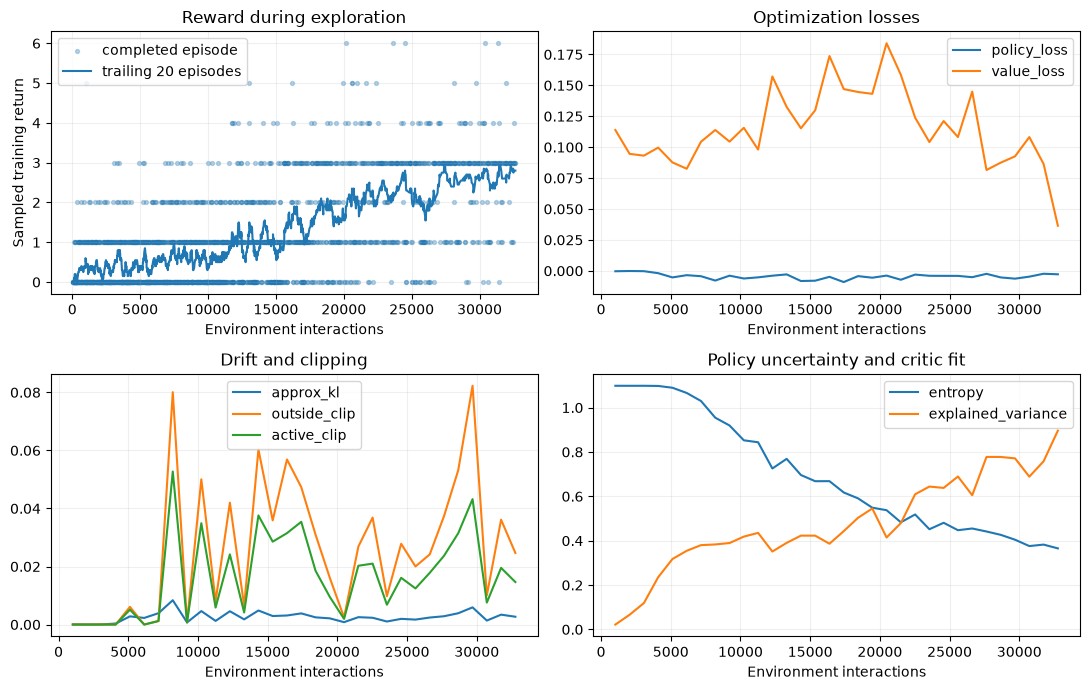

In [18]:
x = [row["steps"] for row in history]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
ax = axes[0, 0]
if episode_returns:
    ax.scatter(episode_steps, episode_returns, s=8, alpha=0.3, label="completed episode")
    smooth = [np.mean(episode_returns[max(0, i-19):i+1]) for i in range(len(episode_returns))]
    ax.plot(episode_steps, smooth, label="trailing 20 episodes")
ax.set(ylabel="Sampled training return", title="Reward during exploration")
ax.legend()

for key in ["policy_loss", "value_loss"]:
    axes[0, 1].plot(x, [row[key] for row in history], label=key)
axes[0, 1].set(title="Optimization losses")
axes[0, 1].legend()
for key in ["approx_kl", "outside_clip", "active_clip"]:
    axes[1, 0].plot(x, [row[key] for row in history], label=key)
axes[1, 0].set(title="Drift and clipping")
axes[1, 0].legend()
for key in ["entropy", "explained_variance"]:
    axes[1, 1].plot(x, [row[key] for row in history], label=key)
axes[1, 1].set(title="Policy uncertainty and critic fit")
axes[1, 1].legend()
for ax in axes.flat:
    ax.set_xlabel("Environment interactions")
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / "training_curves.png", dpi=140)
plt.show()


## 7. Evaluate the frozen trained policy

Use exactly the protocol fixed above. This cell performs no training. Evaluation stops at game-over or the configured cap, and reports how many episodes reached that cap.

The error bars below are **standard errors of episode returns**, not confidence intervals over training seeds. A result from one short training run is a classroom observation. Repeat training with several seeds and a larger fixed evaluation set before drawing a performance conclusion.


Uniform random | return 0.25 +/- 0.10 SE | length 8.5 | capped 0/20
Before PPO     | return 0.70 +/- 0.11 SE | length 13.0 | capped 0/20
After PPO      | return 3.00 +/- 0.15 SE | length 37.9 | capped 0/20


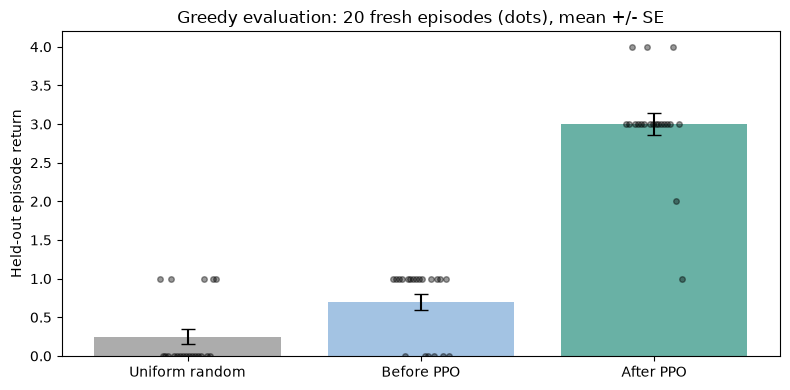

In [19]:
after = evaluate(policy, eval_seeds)
evaluation = {"Uniform random": baseline, "Before PPO": before, "After PPO": after}
fig, ax = plt.subplots(figsize=(8, 4))
summary = {}
for j, (label, rows) in enumerate(evaluation.items()):
    returns = np.array([row["return"] for row in rows])
    mean = float(returns.mean())
    se = float(returns.std(ddof=1) / np.sqrt(len(returns)))
    truncated = sum(row["truncated"] for row in rows)
    summary[label] = {"mean_return": mean, "standard_error": se,
                      "episodes": len(rows), "truncated_episodes": truncated}
    ax.bar(j, mean, alpha=0.65, color=["gray", "#72A4D4", "#188775"][j])
    ax.errorbar(j, mean, yerr=se, fmt="none", color="black", capsize=5)
    ax.scatter(j + np.linspace(-0.12, 0.12, len(returns)), returns, s=16, color="black", alpha=0.4)
    print(f"{label:14s} | return {mean:.2f} +/- {se:.2f} SE | "
          f"length {np.mean([r['length'] for r in rows]):.1f} | capped {truncated}/{len(rows)}")
ax.set(xticks=range(3), xticklabels=list(evaluation), ylabel="Held-out episode return",
       title=f"Greedy evaluation: {EVAL_EPISODES} fresh episodes (dots), mean +/- SE")
fig.tight_layout()
fig.savefig(OUT / "evaluation.png", dpi=140)
plt.show()


## 8. Watch one episode and inspect action probabilities

This separate demonstration seed is outside the training and evaluation seed sets. The existing course renderer shows the board, chosen action, policy probabilities, and critic value. Sticky actions can cause the executed movement to repeat the previous request.

The GIF is embedded in the notebook so it is available for class without retraining. It illustrates one trajectory; the evaluation above measures returns across episodes. Change the seed to explore other trajectories after fixing the reported evaluation panel.


Demo seed 30550 | return 3 | length 38 | terminal True


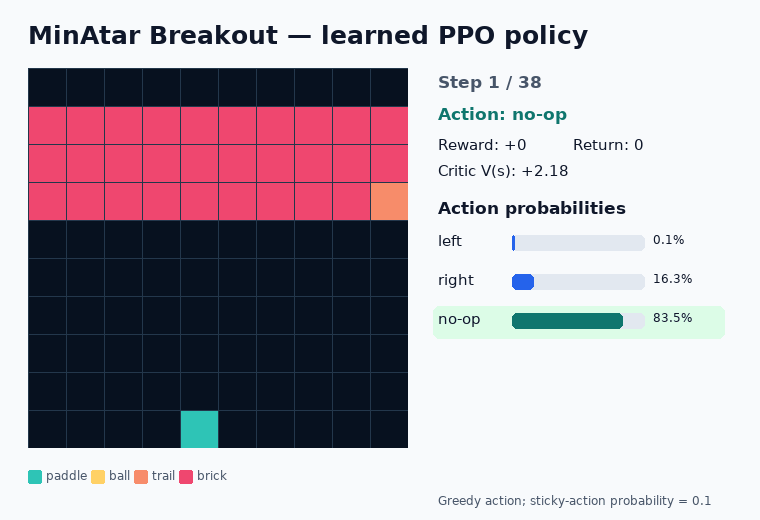

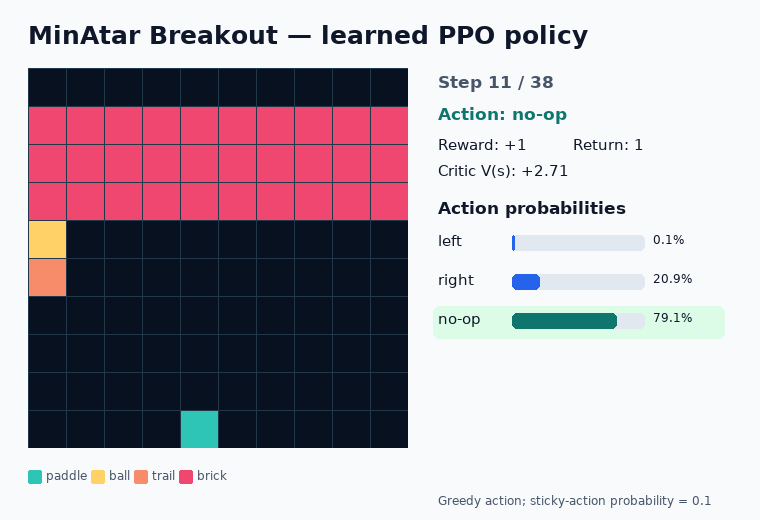

In [20]:
demo_env = MinAtarAdapter("breakout", seed=30_550)
rollout = rollout_minatar_policy(
    demo_env, policy, algorithm="ppo", max_episode_steps=1000, device=str(device),
)
gif_path = save_minatar_policy_animation(
    rollout, OUT / "ppo_rollout.gif", fps=10, max_rendered_frames=200,
)
print(f"Demo seed {rollout.seed} | return {rollout.episode_return:.0f} | "
      f"length {rollout.episode_length} | terminal {rollout.terminated}")
display(Image(data=gif_path.read_bytes(), format="gif"))
display(render_minatar_policy_frame(rollout, step_index=min(10, rollout.episode_length - 1)))


In [21]:
# Keep this notebook's evidence separate from the module's earlier benchmark runs.
with (OUT / "training.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(history[0]))
    writer.writeheader()
    writer.writerows(history)
with (OUT / "evaluation.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["policy", "seed", "return", "length", "truncated"])
    writer.writeheader()
    writer.writerows({"policy": label, **row} for label, rows in evaluation.items() for row in rows)
run_summary = {
    "seed": SEED, "requested_device": DEVICE, "resolved_device": str(device),
    "torch_version": torch.__version__, "minatar_version": version("minatar"),
    "steps": steps, "training_seconds": training_seconds,
    "num_envs": NUM_ENVS, "rollout_steps": ROLLOUT_STEPS, "updates": NUM_UPDATES,
    "update_epochs": UPDATE_EPOCHS, "minibatch_size": MINIBATCH_SIZE,
    "gamma": GAMMA, "gae_lambda": GAE_LAMBDA, "learning_rate": LEARNING_RATE,
    "clip_epsilon": CLIP_EPS, "value_coefficient": VALUE_COEF,
    "entropy_coefficient": ENTROPY_COEF, "target_kl": TARGET_KL,
    "action_names": list(action_names), "raw_action_ids": list(envs[0].raw_action_ids),
    "evaluation_seeds": eval_seeds, "evaluation_max_steps": EVAL_MAX_STEPS,
    "evaluation": summary, "demo_seed": rollout.seed,
    "demo_return": rollout.episode_return, "demo_length": rollout.episode_length,
    "interpretation": "One short training seed; classroom behavior and execution evidence.",
}
(OUT / "summary.json").write_text(json.dumps(run_summary, indent=2) + "\n")
print(f"Figures, tables, run settings, and animation saved in {OUT}")


Figures, tables, run settings, and animation saved in /Users/chen/Documents/ChatGPT/MATH550 coding/output/reinforcement/notebook_demo
